# Will Your Model Survive the Monsoon?
**Model X 2.0 × Zuu Crew · Workshop 01**

**First:** File → Save a copy in Drive, and work in your copy.

**Two problems, one storm.** You run both, cell by cell:
- **Rivers:** forecast tomorrow's flow for the Kelani, Mahaweli and Kalu, and flag floods.
- **Dengue:** forecast cases per district two weeks ahead, and flag outbreaks.

**Fell behind?** Click the first cell of the sprint you're on, then Runtime → Run before.

**Real data:** river flow from the Copernicus GloFAS system, rainfall from Open-Meteo, and dengue from the Ministry of Health's weekly reports. It all ends a few days before today.

This notebook isn't graded. Your graded work is the Ditwah Challenge at the end.

In [ ]:
#@title Setup: run me first (no need to read this cell)

# ---- Where the data lives ----
DATA_URL = "https://raw.githubusercontent.com/machinelearningzuu/the-ditwah-challenge/main/data"   # main copy (GitHub)
DATA_FILES = {                                                                                      # backup copy (Google Drive)
    "rivers_daily": "12z84y2u8IX-gqlGSA63j8G92KS8_FI3C",
    "weekly_district": "1E-DurwmmSf7RSYZKW7wE3UtMFR3GVS4N",
}
FORM_LINK = "https://forms.gle/q6F4W2gWyJPcaqdj9"


# ---- Libraries ----
import os
import base64
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge, PoissonRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")


# ---- Chart style ----
plt.rcParams.update({
    "figure.figsize": (11, 3.4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

BLUE, RED, INK, GREY, GREEN = "#0044FC", "#941515", "#0A0F22", "#AEB6CE", "#2E9E5B"


# ---- The timeline ----
DITWAH = (pd.Timestamp("2025-11-24"), pd.Timestamp("2025-12-07"))   # approximate window
TRAIN_END = pd.Timestamp("2023-11-01")    # train before this date, validate after it
FREEZE = pd.Timestamp("2025-11-01")       # the day the models go live


# ---- The two problems ----
CFG = {
    "rivers": dict(
        target="flow_m3s", unit="m³/s", step=pd.Timedelta(days=1), h=1,
        base="Tomorrow = today", alert_q=0.98, window=7, retrain="30D",
        shock=pd.Timedelta(days=30), every="day", show="Kelani (Hanwella)",
        drift=["rain_3d", "rain_7d", "rain_30d", "flow_today"],
    ),
    "dengue": dict(
        target="cases", unit="cases", step=pd.Timedelta(weeks=1), h=2,
        base="Last published week", alert_q=0.90, window=4, retrain="4W-MON",
        shock=pd.Timedelta(weeks=10), every="week", show="Colombo",
        drift=["rain_last_week", "rain_4w", "rain_max_day", "cases_published"],
    ),
}
TRACKS = ["rivers", "dengue"]

_LEAKS = set(base64.b64decode("QkNERQ==").decode())    # the answer key, lightly hidden
NOT_FEATURES = {"date", "place", "y", "persistence", "seasonal", "moving_avg"}


# ---- Loading ----
EXPECTED = {"rivers_daily": "date,", "weekly_district": "week,"}     # how each file's first line starts


def _is_csv(raw, name):
    return raw.lstrip(b"\xef\xbb\xbf").startswith(EXPECTED[name].encode())


def _download(name):
    path = f"/content/{name}.csv"

    # already downloaded in this session, and it really is the CSV
    if os.path.exists(path) and _is_csv(open(path, "rb").read(64), name):
        return pd.read_csv(path)

    file_id = DATA_FILES[name]
    sources = [
        f"{DATA_URL}/{name}.csv",                                                              # GitHub first
        f"https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t",   # then Drive
        f"https://drive.google.com/uc?export=download&id={file_id}",
    ]

    for url in sources:
        try:
            r = requests.get(url, timeout=30)
        except Exception:
            continue

        # Drive sometimes sends a web page instead of the file: only keep it if it's really the CSV
        if r.status_code == 200 and _is_csv(r.content[:64], name):
            with open(path, "wb") as f:
                f.write(r.content)
            return pd.read_csv(path)

    raise AssertionError(
        f"Couldn't download {name}.csv. Open https://drive.google.com/file/d/{file_id} in your browser, "
        f"download it, drag it into the Files panel on the left, then run this cell again."
    )


def load_track(track):
    if track == "rivers":
        d = _download("rivers_daily")
        d = d.rename(columns={"river": "place", "catchment_rain_mm": "rain"})
        keep = ["date", "place", "flow_m3s", "rain"]
    else:
        d = _download("weekly_district")
        assert d["cases"].notna().sum() > 0, "weekly_district.csv downloaded, but it has no dengue cases. Tell a TA."
        d = d.rename(columns={"district": "place", "rain_mm": "rain", "week": "date"})
        d["source"] = d["source"].fillna("")
        keep = ["date", "place", "cases", "rain", "rain_max_day", "temp_mean", "source"]

    d["date"] = pd.to_datetime(d["date"])
    assert len(d) > 1000, f"The {track} data looks incomplete ({len(d)} rows). Run this cell again."
    return d[keep].sort_values(["place", "date"]).reset_index(drop=True)


# ---- Scoring ----
def mae(actual, predicted):
    a = np.asarray(actual, float)
    p = np.asarray(predicted, float)
    ok = ~(np.isnan(a) | np.isnan(p))
    return float(np.mean(np.abs(a[ok] - p[ok])))


def feats_of(X):
    return [c for c in X.columns if c not in NOT_FEATURES]


# ---- Two model families ----
class Regression:
    """Rivers: ridge regression on log flow. Dengue: Poisson regression.
    Both can forecast above anything seen in training."""

    def __init__(self, track):
        self.track = track

    def _prep(self, X):
        X = X.copy()
        if self.track == "rivers":
            for c in X.columns:
                if c.startswith(("flow", "rain")):
                    X[c] = np.log1p(X[c].clip(lower=0))
        return X

    def fit(self, X, y, sample_weight=None):
        if self.track == "rivers":
            self.m = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
            self.m.fit(self._prep(X), np.log1p(y), ridge__sample_weight=sample_weight)
        else:
            self.m = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-3, max_iter=2000))
            self.m.fit(self._prep(X), y, poissonregressor__sample_weight=sample_weight)
        return self

    def predict(self, X):
        p = self.m.predict(self._prep(X))
        if self.track == "rivers":
            return np.expm1(np.clip(p, None, 15))
        return p


def Boosting():
    """Gradient boosting: strong on normal days, but it can't forecast above its training range."""
    return HistGradientBoostingRegressor(loss="poisson", max_iter=250, learning_rate=0.06, random_state=0)


# ---- Small helpers ----
def in_shock(dates, track):
    return (dates >= DITWAH[0]) & (dates <= DITWAH[1] + CFG[track]["shock"])


def episodes(flags):
    """(start, end) of each run of True in a date-indexed series."""
    f = flags.astype(bool)
    starts = f & ~f.shift(1, fill_value=False)
    ends = f & ~f.shift(-1, fill_value=False)
    return list(zip(f.index[starts], f.index[ends]))


def shade(ax):
    ax.axvspan(DITWAH[0], DITWAH[1], color=RED, alpha=0.15, lw=0)
    ax.axvline(FREEZE, color=GREY, ls=":", lw=1)


print("Setup done.")

Setup done.


In [ ]:
#@title Meet the data: what's in each table?

from IPython.display import display

# stops with a clear error if a file didn't download
DATA = {track: load_track(track) for track in TRACKS}

for track in TRACKS:
    d = DATA[track]
    print(f"{track}: {len(d):,} rows · {d.place.nunique()} places · {d.date.min().date()} to {d.date.max().date()}")

# what each column means
COLUMNS = {
    "rivers": {
        "date": "the day",
        "place": "the river, and the gauge we read it at",
        "flow_m3s": "river flow that day, in cubic metres per second (what we forecast)",
        "rain": "rain over the river's catchment that day, in mm",
    },
    "dengue": {
        "date": "the week (starts on a Monday)",
        "place": "the district (all 25)",
        "cases": "dengue cases reported that week (what we forecast)",
        "rain": "total rain that week, in mm",
        "rain_max_day": "the wettest single day that week, in mm",
        "temp_mean": "average temperature that week, in °C",
        "source": "which report the count came from: WER (Epidemiology Unit) or NDCU (National Dengue Control Unit)",
    },
}

for track in TRACKS:
    d = DATA[track]
    print(f"\n{track.upper()}: {len(d):,} rows, one per {CFG[track]['every']} for each place")

    for col, meaning in COLUMNS[track].items():
        print(f"  {col:14s} {meaning}")

    display(d.head(3).round(1))


# the same tables during Ditwah
kelani = DATA["rivers"][DATA["rivers"].place == "Kelani (Hanwella)"]
print("\nRIVERS during Ditwah: the Kelani at Hanwella")
display(kelani[(kelani.date >= "2025-11-24") & (kelani.date <= "2025-12-02")].round(1))

colombo = DATA["dengue"][DATA["dengue"].place == "Colombo"]
print("\nDENGUE around Ditwah: Colombo (a blank means no report that week)")
display(colombo[(colombo.date >= "2025-11-10") & (colombo.date <= "2026-01-12")].round(1))

rivers: 12,906 rows · 3 places · 2015-01-01 to 2026-10-11
dengue: 15,375 rows · 25 places · 2014-12-29 to 2026-10-05

RIVERS: 12,906 rows, one per day for each place
  date           the day
  place          the river, and the gauge we read it at
  flow_m3s       river flow that day, in cubic metres per second (what we forecast)
  rain           rain over the river's catchment that day, in mm


,date,place,flow_m3s,rain
0,2015-01-01,Kalu (Ratnapura),135.8,3.0
1,2015-01-02,Kalu (Ratnapura),126.9,0.0
2,2015-01-03,Kalu (Ratnapura),118.4,0.2



DENGUE: 15,375 rows, one per week for each place
  date           the week (starts on a Monday)
  place          the district (all 25)
  cases          dengue cases reported that week (what we forecast)
  rain           total rain that week, in mm
  rain_max_day   the wettest single day that week, in mm
  temp_mean      average temperature that week, in °C
  source         which report the count came from: WER (Epidemiology Unit) or NDCU (National Dengue Control Unit)


,date,place,cases,rain,rain_max_day,temp_mean,source
0,2014-12-29,Ampara,NaN,3.1,1.8,25.9,
1,2015-01-05,Ampara,36.0,6.5,3.3,25.0,WER
2,2015-01-12,Ampara,57.0,4.6,1.5,24.9,WER



RIVERS during Ditwah: the Kelani at Hanwella


,date,place,flow_m3s,rain
8282,2025-11-24,Kelani (Hanwella),310.9,23.7
8283,2025-11-25,Kelani (Hanwella),331.7,20.6
8284,2025-11-26,Kelani (Hanwella),511.9,42.1
8285,2025-11-27,Kelani (Hanwella),516.6,155.7
8286,2025-11-28,Kelani (Hanwella),900.6,212.2
8287,2025-11-29,Kelani (Hanwella),1357.3,8.2
8288,2025-11-30,Kelani (Hanwella),1027.0,0.0
8289,2025-12-01,Kelani (Hanwella),736.9,0.8
8290,2025-12-02,Kelani (Hanwella),644.6,0.6



DENGUE around Ditwah: Colombo (a blank means no report that week)


,date,place,cases,rain,rain_max_day,temp_mean,source
3027,2025-11-10,Colombo,266.0,43.1,13.0,26.2,WER
3028,2025-11-17,Colombo,226.0,89.9,25.5,25.6,WER
3029,2025-11-24,Colombo,286.0,375.2,204.6,24.8,WER
3030,2025-12-01,Colombo,272.0,38.6,19.8,25.9,WER
3031,2025-12-08,Colombo,318.0,40.7,15.3,25.6,WER
3032,2025-12-15,Colombo,340.0,32.4,16.5,25.9,WER
3033,2025-12-22,Colombo,NaN,3.4,1.6,26.7,WER
3034,2025-12-29,Colombo,388.0,9.8,2.9,27.2,WER
3035,2026-01-05,Colombo,434.0,27.2,10.5,25.6,WER
3036,2026-01-12,Colombo,594.0,22.4,13.6,25.7,WER


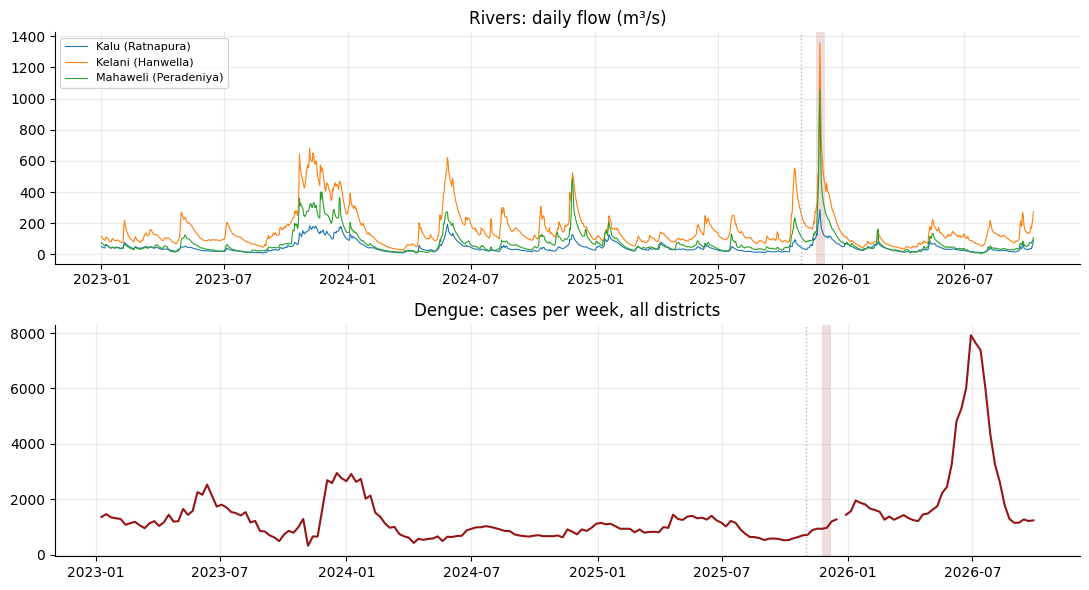

Red band: Ditwah (approx.). Dotted line: 1 November 2025, when our models go live.


In [ ]:
#@title Load both datasets and draw the timeline

fig, axes = plt.subplots(2, 1, figsize=(11, 6))

# Rivers: daily flow since 2023
recent = DATA["rivers"][DATA["rivers"].date >= "2023-01-01"]
for river, g in recent.groupby("place"):
    axes[0].plot(g.date, g.flow_m3s, lw=0.8, label=river)
axes[0].set_title("Rivers: daily flow (m³/s)")
axes[0].legend(fontsize=8, loc="upper left")

# Dengue: weekly cases since 2023, all districts together
recent = DATA["dengue"][DATA["dengue"].date >= "2023-01-01"]
weekly = recent.groupby("date").cases.sum(min_count=1)
axes[1].plot(weekly.index, weekly.values, color=RED)
axes[1].set_title("Dengue: cases per week, all districts")

for ax in axes:
    shade(ax)

plt.tight_layout()
plt.show()

print("Red band: Ditwah (approx.). Dotted line: 1 November 2025, when our models go live.")

---
## Sprint 1 · Meet the data  *(Design)*
A warning is only useful if someone can act on it. Before any model, answer: **who acts, how far ahead, and on what?**

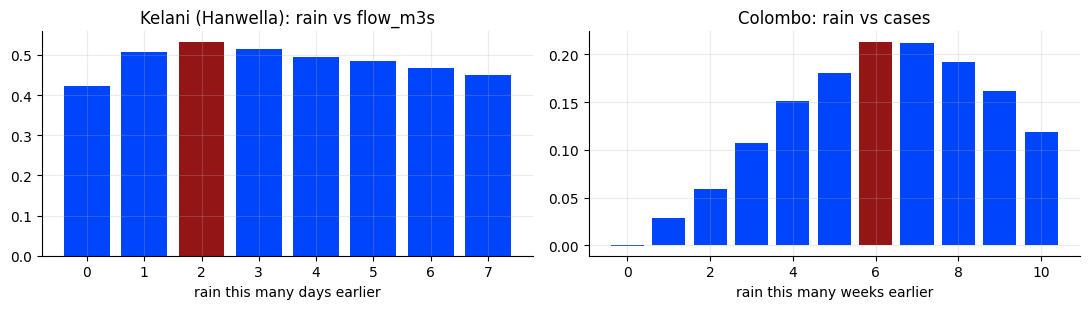

Rivers: rain shows up in the Kelani (Hanwella) 2 day(s) later.
Dengue: rain shows up in Colombo's cases 6 week(s) later.
That delay is the lead time a warning can use.


In [ ]:
#@title 1a · How long after the rain does it show up?

LEAD = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))

for ax, track in zip(axes, TRACKS):
    c = CFG[track]
    d = DATA[track][DATA[track].place == c["show"]].set_index("date")
    lags = range(0, 8) if track == "rivers" else range(0, 11)

    # correlation between the outcome and the rain k steps earlier
    corr = [d[c["target"]].corr(d.rain.shift(k)) for k in lags]
    LEAD[track] = int(np.nanargmax(corr))

    colors = [RED if k == LEAD[track] else BLUE for k in lags]
    ax.bar(list(lags), corr, color=colors)
    ax.set_title(f"{c['show']}: rain vs {c['target']}")
    ax.set_xlabel(f"rain this many {c['every']}s earlier")

plt.tight_layout()
plt.show()

print(f"Rivers: rain shows up in the {CFG['rivers']['show']} {LEAD['rivers']} day(s) later.")
print(f"Dengue: rain shows up in {CFG['dengue']['show']}'s cases {LEAD['dengue']} week(s) later.")
print("That delay is the lead time a warning can use.")

In [ ]:
#@title 1b · Where is the alert line? (set from the training years only)

LINE = {}

for track in TRACKS:
    c = CFG[track]
    train_years = DATA[track][DATA[track].date < TRAIN_END]
    LINE[track] = train_years.groupby("place")[c["target"]].quantile(c["alert_q"])

print("Flood line: the top 2% of days (m³/s)")
print(LINE["rivers"].round(0).to_string())

print("\nOutbreak line: the top 10% of weeks (cases per week), biggest districts")
print(LINE["dengue"].sort_values(ascending=False).head(8).round(0).to_string())

Flood line: the top 2% of days (m³/s)
place
Kalu (Ratnapura)         129.0
Kelani (Hanwella)        442.0
Mahaweli (Peradeniya)    261.0

Outbreak line: the top 10% of weeks (cases per week), biggest districts
place
Colombo       532.0
Gampaha       386.0
Kandy         255.0
Kalutara      189.0
Batticaloa    163.0
Jaffna        149.0
Galle         128.0
Puttalam      125.0


**Your warning statement.** Double-click and fill it in, for rivers or for dengue:

> Warn **[who]** that **[what]** will cross the alert line **[how far ahead]**, so they can **[do what]**.

---
## Sprint 2 · Build it honestly  *(Build)*
The feature code below has five blocks, **A to E**, and they're the same five for both problems. Four of them leak information you wouldn't have at decision time. One is fine.

**Your job:** read the blocks, decide which ones leak, and flip their switch to `True` in cell 2b. Rerun 2b after each flip and watch both scores.

In [ ]:
# 2a · The features (read this!)

def make_features(d, track, fix, h=None):
    c = CFG[track]
    h = h or c["h"]
    t = c["target"]

    # alert lines and averages: from every year, or from the training years only
    line_all = d.groupby("place")[t].quantile(c["alert_q"])
    line_train = d[d.date < TRAIN_END].groupby("place")[t].quantile(c["alert_q"])
    avg_all = d.groupby("place")[t].mean()
    avg_train = d[d.date < TRAIN_END].groupby("place")[t].mean()

    rows = []
    for place, g in d.groupby("place"):
        g = g.sort_values("date")
        s = g[t]

        # y = the answer we're trying to forecast, h steps ahead
        X = pd.DataFrame({"date": g.date.values, "place": place, "y": s.shift(-h).values})

        if track == "rivers":
            X["flow_today"] = s.values
            X["rain_today"] = g.rain.values
            X["rain_3d"] = g.rain.rolling(3).sum().values
            X["rain_7d"] = g.rain.rolling(7).sum().values
            X["rain_30d"] = g.rain.rolling(30).sum().values

            # ---- Block A ----
            X["flow_yesterday"] = s.shift(2 if fix["A"] else 1).values

            # ---- Block B ----
            X["rain_next_day"] = (g.rain.shift(1) if fix["B"] else g.rain.shift(-1)).values

            # ---- Block C ----
            X["flow_week_avg"] = s.rolling(7, center=not fix["C"]).mean().values

            # ---- Block D ----
            line = line_train if fix["D"] else line_all
            X["above_line"] = (s > line[place]).astype(int).values

            # baselines (not features)
            X["persistence"] = s.values                    # tomorrow = today
            X["seasonal"] = s.shift(365 - h).values        # same day last year
            X["moving_avg"] = s.rolling(7).mean().values   # last 7 days

        else:
            published = s.shift(2)                         # reports arrive about 2 weeks late
            X["cases_published"] = published.values
            X["cases_published_prev"] = s.shift(3).values
            X["rain_last_week"] = g.rain.shift(1).values
            X["rain_4w"] = g.rain.shift(1).rolling(4).sum().values
            X["rain_max_day"] = g.rain_max_day.shift(1).values
            X["temp_4w"] = g.temp_mean.shift(1).rolling(4).mean().values

            # ---- Block A ----
            X["rain_3w_ago"] = g.rain.shift(6 if fix["A"] else 3).values

            # ---- Block B ----
            X["cases_this_week"] = (s.shift(2) if fix["B"] else s).values

            # ---- Block C ----
            centred = s.rolling(4, center=True).mean()
            X["cases_4w_avg"] = (published.rolling(4).mean() if fix["C"] else centred).values

            # ---- Block D ----
            avg = avg_train if fix["D"] else avg_all
            X["district_avg"] = avg[place]

            # baselines (not features)
            X["persistence"] = published.values            # last published week
            X["seasonal"] = s.shift(52 - h).values         # same week last year
            X["moving_avg"] = published.rolling(4).mean().values

        day = g.date.dt.dayofyear.values
        X["season_sin"] = np.sin(2 * np.pi * day / 365.25)
        X["season_cos"] = np.cos(2 * np.pi * day / 365.25)
        rows.append(X)

    X = pd.concat(rows, ignore_index=True)
    return X.join(pd.get_dummies(X.place, prefix="at", dtype=int))


def split(X, fix, track):
    X = X.dropna(subset=["y"])
    gap = CFG[track]["step"] * CFG[track]["h"]

    # ---- Block E ----
    if fix["E"]:
        # rows whose answer lands after a cutoff stay out of that side
        train = X[X.date < TRAIN_END - gap]
        test = X[(X.date >= TRAIN_END) & (X.date < FREEZE - gap)]
        return train, test

    return train_test_split(X, test_size=0.25, random_state=0)


print("Features ready. Now flip switches in 2b.")

Features ready. Now flip switches in 2b.


In [ ]:
# 2b · Flip a switch to True when you think that block leaks. Rerun after every flip.

fix = {"A": False, "B": True, "C": True, "D": True, "E": True}

for track in TRACKS:
    c = CFG[track]
    X = make_features(DATA[track], track, fix)
    F = feats_of(X)

    tr, te = split(X, fix, track)
    tr = tr.dropna(subset=F)
    te = te.dropna(subset=F)

    model = Boosting().fit(tr[F], tr.y)
    err = mae(te.y, model.predict(te[F]))
    base = mae(te.y, te.persistence)

    print(f"{track:7s} error {err:,.1f} {c['unit']} · baseline ({c['base']}) {base:,.1f} · skill {1 - err / base:+.0%}")


found = len([k for k in _LEAKS if fix[k]])
decoy = [k for k in fix if fix[k] and k not in _LEAKS]

print(f"\nLeaks fixed: {found} of 4")

if decoy:
    print(f"{decoy[0]} wasn't a leak. Flip it back.")

if found == 4 and not decoy:
    print("All leaks fixed. These are your honest scores.")

rivers  error 4.0 m³/s · baseline (Tomorrow = today) 6.0 · skill +33%
dengue  error 14.4 cases · baseline (Last published week) 26.3 · skill +45%

Leaks fixed: 1 of 4


In [ ]:
#@title 2c · The honest comparison: baselines vs two models

HONEST = {"A": False, "B": True, "C": True, "D": True, "E": True}
NORMAL, NORMAL_ALL = {}, {}

for track in TRACKS:
    c = CFG[track]
    X = make_features(DATA[track], track, HONEST)
    F = feats_of(X)

    tr, te = split(X, HONEST, track)
    tr = tr.dropna(subset=F)
    te = te.dropna(subset=F)

    results = {
        "Baseline: " + c["base"]: te.persistence.values,
        "Baseline: same time last year": te.seasonal.values,
        "Baseline: recent average": te.moving_avg.values,
        "Regression": Regression(track).fit(tr[F], tr.y).predict(te[F]),
        "Gradient boosting": Boosting().fit(tr[F], tr.y).predict(te[F]),
    }

    base = mae(te.y, te.persistence)
    table = pd.DataFrame({"error": {k: mae(te.y, v) for k, v in results.items()}})
    table["skill vs baseline"] = (1 - table.error / base).map("{:+.0%}".format)

    print(f"\n{track.upper()} · validation {TRAIN_END.date()} to {FREEZE.date()} (before Ditwah)")
    print(table.round(1).to_string())

    # each place's normal error: the alarm compares against this later
    boost = results["Gradient boosting"]
    NORMAL[track] = te.assign(e=np.abs(te.y - boost)).groupby("place").e.mean()
    NORMAL_ALL[track] = mae(te.y, boost)


RIVERS · validation 2023-11-01 to 2025-11-01 (before Ditwah)
                               error skill vs baseline
Baseline: Tomorrow = today       7.9               +0%
Baseline: same time last year   75.6             -862%
Baseline: recent average        19.5             -148%
Regression                       6.6              +16%
Gradient boosting                7.3               +7%

DENGUE · validation 2023-11-01 to 2025-11-01 (before Ditwah)
                               error skill vs baseline
Baseline: Last published week   17.2               +0%
Baseline: same time last year   30.5              -77%
Baseline: recent average        18.9              -10%
Regression                      20.9              -22%
Gradient boosting               16.1               +7%


---
## Freeze  *(Deploy)*
It's **1 November 2025**. You ship both models. Forecasts go out every day for the rivers and every week for dengue. Nobody knows what's coming.

In [ ]:
#@title Freeze both models

FEATURES, KNOWN, TRAIN_ROWS, FROZEN, CEILING, TRAIN_MAX = {}, {}, {}, {}, {}, {}

for track in TRACKS:
    c = CFG[track]
    X = make_features(DATA[track], track, HONEST)
    F = feats_of(X)

    FEATURES[track] = (X, F)
    KNOWN[track] = X.dropna(subset=F + ["y"])

    # only answers you'd have known by go-live day
    train = KNOWN[track][KNOWN[track].date < FREEZE - c["step"] * c["h"]]
    TRAIN_ROWS[track] = train

    FROZEN[track] = {
        "Regression": Regression(track).fit(train[F], train.y),
        "Gradient boosting": Boosting().fit(train[F], train.y),
    }

    CEILING[track] = train.groupby("place").y.max()     # the highest value the models have ever seen
    TRAIN_MAX[track] = train[c["drift"]].max()

    print(f"{track}: frozen on {len(train):,} rows up to {FREEZE.date()}. Forecasts now go out every {c['every']}.")

print("\nStop here. After the break, Ditwah hits.")

rivers: frozen on 11,781 rows up to 2025-11-01. Forecasts now go out every day.
dengue: frozen on 11,151 rows up to 2025-11-01. Forecasts now go out every week.

Stop here. After the break, Ditwah hits.


---
## Sprint 3 · The Ditwah stress test  *(Monitor)*
We run both frozen models forward through Ditwah, exactly as they would have run live. The **alarm** fires when a model's recent error passes **double its normal error**. Errors only count once their answer is known.

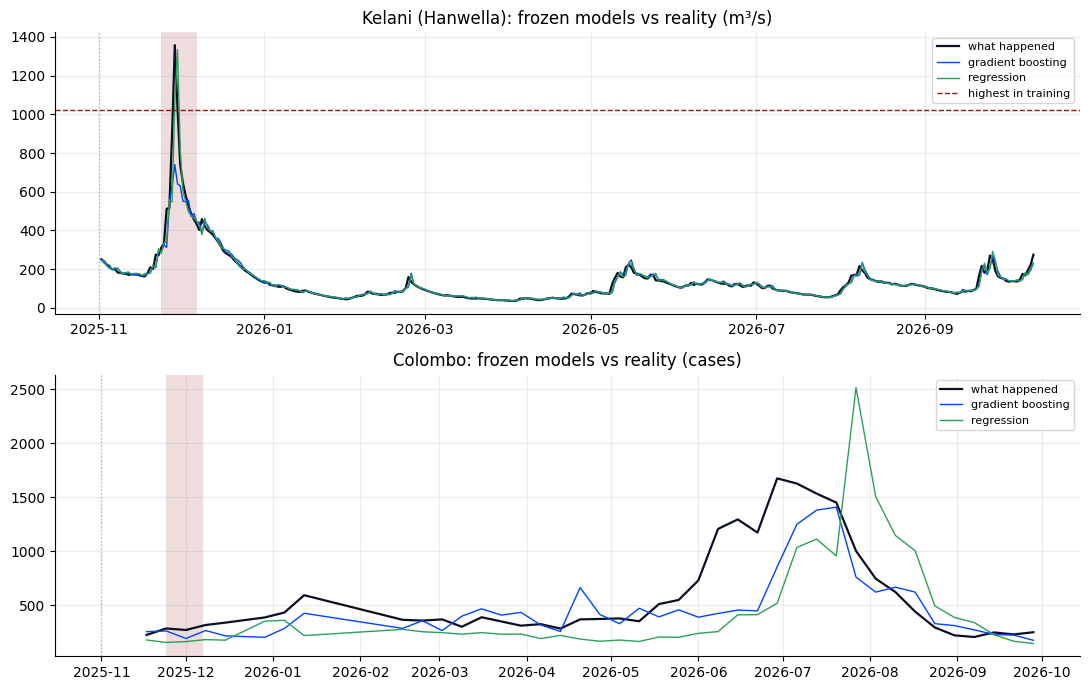


RIVERS · Kelani (Hanwella)
  Alarm fired 2025-11-26, cleared after 2025-12-15.
  It fired 1 more time(s) later, the first on 2026-09-25.
  Highest after go-live: 1,357 m³/s for 2025-11-29. Boosting said 740, regression 1,055.

DENGUE · Colombo
  Alarm fired 2026-02-09, cleared after 2026-02-16.
  It fired 2 more time(s) later, the first on 2026-06-01.
  Highest after go-live: 1,676 cases for 2026-06-29. Boosting said 857, regression 519.


In [ ]:
#@title 3a · Run the frozen models through Ditwah

LIVE = {}

for track in TRACKS:
    c = CFG[track]
    X, F = FEATURES[track]
    live = X[X.date >= FREEZE].dropna(subset=F + ["y"]).copy()

    for name, model in FROZEN[track].items():
        live[name] = model.predict(live[F])

    # the alarm: recent error vs normal error, counting only errors whose answer is already known
    live["err"] = (live.y - live["Gradient boosting"]).abs()
    live["err_known"] = live.groupby("place").err.shift(c["h"])
    live["recent_err"] = live.groupby("place").err_known.transform(lambda s: s.rolling(c["window"], min_periods=2).mean())
    live["alarm"] = live.recent_err > 2 * live.place.map(NORMAL[track])

    LIVE[track] = live


fig, axes = plt.subplots(2, 1, figsize=(11, 7))

for ax, track in zip(axes, TRACKS):
    c = CFG[track]
    g = LIVE[track][LIVE[track].place == c["show"]]
    when = g.date + c["step"] * c["h"]          # the day or week being forecast

    ax.plot(when, g.y, color=INK, lw=1.6, label="what happened")
    ax.plot(when, g["Gradient boosting"], color=BLUE, lw=1, label="gradient boosting")
    ax.plot(when, g["Regression"], color=GREEN, lw=1, label="regression")

    if track == "rivers":
        ax.axhline(CEILING[track][c["show"]], color=RED, ls="--", lw=1, label="highest in training")

    ax.set_title(f"{c['show']}: frozen models vs reality ({c['unit']})")
    ax.legend(fontsize=8)
    shade(ax)

plt.tight_layout()
plt.show()


for track in TRACKS:
    c = CFG[track]
    g = LIVE[track][LIVE[track].place == c["show"]]
    eps = episodes(g.set_index("date").alarm)

    print(f"\n{track.upper()} · {c['show']}")

    if not eps:
        print("  The alarm never fired.")
    else:
        first = next((e for e in eps if e[1] >= DITWAH[0]), eps[0])
        if first[1] < g.date.max():
            print(f"  Alarm fired {first[0].date()}, cleared after {first[1].date()}.")
        else:
            print(f"  Alarm fired {first[0].date()} and hasn't cleared.")

        later = [e for e in eps if e[0] > first[1]]
        if later:
            print(f"  It fired {len(later)} more time(s) later, the first on {later[0][0].date()}.")

    peak = g.loc[g.y.idxmax()]
    day = (peak.date + c["step"] * c["h"]).date()
    print(f"  Highest after go-live: {peak.y:,.0f} {c['unit']} for {day}. "
          f"Boosting said {peak['Gradient boosting']:,.0f}, regression {peak['Regression']:,.0f}.")

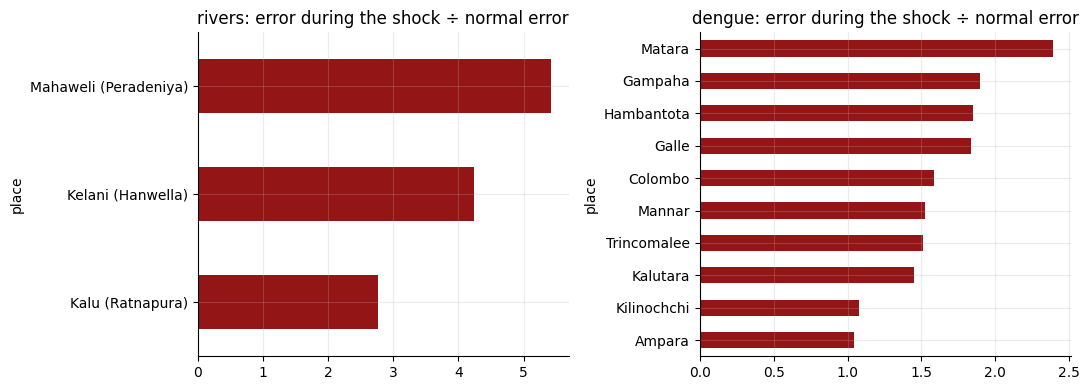

In [ ]:
#@title 3b · Where did it fail people most?

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, track in zip(axes, TRACKS):
    live = LIVE[track]
    shock = live[in_shock(live.date, track)]

    worst = shock.groupby("place").err.mean() / NORMAL[track]
    worst = worst.dropna().sort_values(ascending=False)

    worst.head(10)[::-1].plot.barh(ax=ax, color=RED)
    ax.set_title(f"{track}: error during the shock ÷ normal error")

plt.tight_layout()
plt.show()

### Diagnose the drift
- **3c, data drift:** did the inputs go somewhere the models had never seen?
- **3d, concept drift:** did the link between rain and the outcome change?
- **3e, the ceiling and the counting:** did the river go above anything in training, and did the dengue reporting itself change?

In [ ]:
#@title 3c · Data drift: did the inputs go somewhere the model had never seen?

def psi(train_values, new_values, bins=10):
    a = np.asarray(train_values, float)
    b = np.asarray(new_values, float)

    edges = np.unique(np.nanquantile(a, np.linspace(0, 1, bins + 1)))
    pa = np.histogram(a, edges)[0] / len(a) + 1e-6
    pb = np.histogram(np.clip(b, edges[0], edges[-1]), edges)[0] / max(len(b), 1) + 1e-6

    return float(np.sum((pb - pa) * np.log(pb / pa)))


for track in TRACKS:
    c = CFG[track]
    train = TRAIN_ROWS[track]
    shock = LIVE[track][in_shock(LIVE[track].date, track)]

    report = pd.DataFrame({
        f: {
            "drift score (PSI)": psi(train[f], shock[f]),
            "% of shock rows above anything in training": (shock[f] > TRAIN_MAX[track][f]).mean() * 100,
        }
        for f in c["drift"]
    }).T

    print(f"\n{track.upper()}")
    print(report.round(2).to_string())

print("\nPSI above 0.25 means a big shift. Rows above the training range are where models are guessing.")


RIVERS
            drift score (PSI)  % of shock rows above anything in training
rain_3d                  1.30                                        2.27
rain_7d                  1.60                                        2.27
rain_30d                 4.24                                        0.00
flow_today               5.17                                        2.27

DENGUE
                 drift score (PSI)  % of shock rows above anything in training
rain_last_week                1.52                                        2.29
rain_4w                       1.99                                        0.00
rain_max_day                  0.60                                        1.14
cases_published               0.15                                        0.00

PSI above 0.25 means a big shift. Rows above the training range are where models are guessing.


In [ ]:
#@title 3d · Concept drift: did the link between rain and the outcome change?

TEST = {
    "rivers": ("rain_3d", "flow_today"),          # (the rain feature, what we hold fixed)
    "dengue": ("rain_4w", "cases_published"),
}


def rain_effect(rows, track, feature, anchor):
    model = Regression(track).fit(rows[[anchor, feature]], rows.y)
    return model.m[-1].coef_[1]


for track in TRACKS:
    c = CFG[track]
    feature, anchor = TEST[track]
    known = KNOWN[track]

    before = known[(known.date >= TRAIN_END) & (known.date < FREEZE)]
    after = known[known.date > DITWAH[1] + c["shock"]]

    b = rain_effect(before, track, feature, anchor)
    a = rain_effect(after, track, feature, anchor)
    change = abs(a - b) / max(abs(b), 1e-9)

    print(f"\n{track.upper()} · effect of {feature}: before Ditwah {b:+.3f}, after the shock {a:+.3f} ({change:.0%} change)")

    if change > 0.3:
        print("  A big, lasting change. That's concept drift: retrain on recent data.")
    else:
        print("  About the same. The relationship held; the shock was in the inputs, not the rules.")


RIVERS · effect of rain_3d: before Ditwah +0.046, after the shock +0.041 (11% change)
  About the same. The relationship held; the shock was in the inputs, not the rules.

DENGUE · effect of rain_4w: before Ditwah +0.361, after the shock +0.533 (48% change)
  A big, lasting change. That's concept drift: retrain on recent data.


In [ ]:
#@title 3e · The ceiling (rivers) and the counting (dengue)

# ---- Rivers: did reality go above the highest day in training? ----
live = LIVE["rivers"]
shock = live[in_shock(live.date, "rivers")]
above = shock[shock.y > shock.place.map(CEILING["rivers"])]

print(f"RIVERS · {len(above)} shock days went above the highest flow in training.")

if len(above):
    print(f"  On those days boosting's highest forecast was {above['Gradient boosting'].max():,.0f} m³/s. "
          f"Regression reached {above['Regression'].max():,.0f}.")


# ---- Dengue: is the counting itself changing? ----
d = DATA["dengue"]
after = d[d.date >= FREEZE]
weekly = after.groupby("date").cases.sum(min_count=1)
last_report = after.loc[after.cases.notna(), "date"].max()
missing = weekly[weekly.isna() & (weekly.index <= last_report)]

print("\nDENGUE")
print("  Weeks with no report at all since go-live:", [str(x.date()) for x in missing.index] or "none")

prev = d.groupby("place").source.shift(1)
switch = d[(d.source != prev) & prev.notna() & (prev != "") & (d.source != "")]

for when, src in switch.drop_duplicates("date")[["date", "source"]].itertuples(index=False):
    print(f"  From {when.date()} the counts come from a different source ({src}). Same disease, different counting.")

window = weekly[(weekly.index >= DITWAH[0]) & (weekly.index <= DITWAH[1] + CFG["dengue"]["shock"])].dropna()
drop = (weekly / weekly.rolling(4, min_periods=2).mean().shift(1)).reindex(window.index)

print("  Weeks around Ditwah where reports fell 40%+ below the month before:", [str(x.date()) for x in drop[drop < 0.6].index] or "none")

RIVERS · 4 shock days went above the highest flow in training.
  On those days boosting's highest forecast was 740 m³/s. Regression reached 1,333.

DENGUE
  Weeks with no report at all since go-live: ['2025-12-22']
  From 2026-02-23 the counts come from a different source (NDCU). Same disease, different counting.
  Weeks around Ditwah where reports fell 40%+ below the month before: none


**Finish the line, for each problem:** *"Our model broke because…"*

---
## Sprint 4 · Pick a policy  *(Retrain + deploy)*
You don't pick a model. You pick a **policy**: a model, an alarm, a fallback and a retrain rule. Six options, scored on the shock and the recovery separately.


RIVERS (m³/s)
                            shock error  recovery error
Switch to regression               25.8             3.8
Hybrid                             27.5             4.0
Retrain, Ditwah flagged            30.1             4.1
Frozen boosting                    32.1             4.0
Retrain monthly                    32.2             4.1
Fall back to baseline              36.3             4.0
Baseline: Tomorrow = today         36.5             4.6

DENGUE (cases)
                               shock error  recovery error
Frozen boosting                       17.9            44.3
Hybrid                                18.1            44.3
Fall back to baseline                 19.4            65.1
Baseline: Last published week         19.9            68.2
Retrain, Ditwah flagged               20.1            50.5
Retrain monthly                       20.4            49.5
Switch to regression                  30.3            72.2


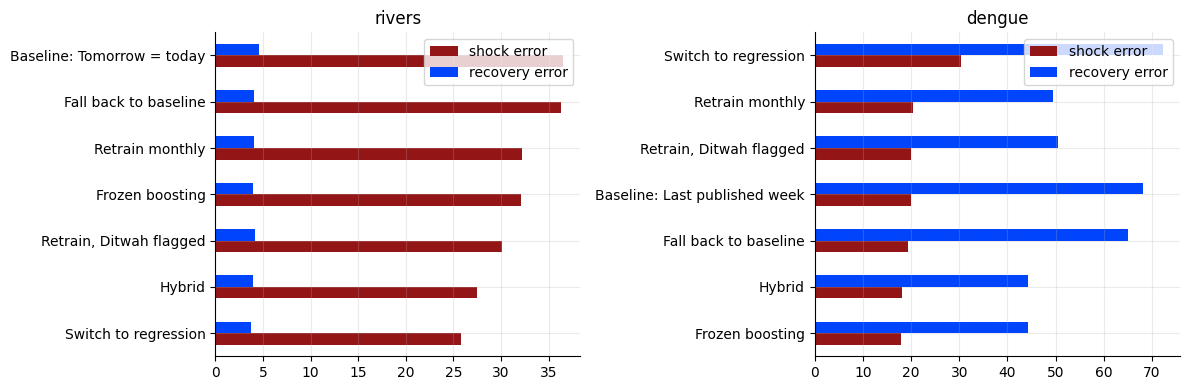

In [ ]:
#@title 4a · Compare six policies on the shock and the recovery

RESULTS = {}


def retrained(track, flagged):
    """Retrain boosting on a schedule, using only answers known by each retrain day."""
    c = CFG[track]
    test = LIVE[track]
    known = KNOWN[track]
    X, F = FEATURES[track]
    gap = c["step"] * c["h"]

    pred = np.full(len(test), np.nan)
    starts = list(pd.date_range(FREEZE, test.date.max(), freq=c["retrain"])) + [test.date.max() + c["step"]]

    for start, end in zip(starts[:-1], starts[1:]):
        rows = known[known.date < start - gap]
        weight = np.where(in_shock(rows.date, track), 0.2, 1.0) if flagged else None
        model = Boosting().fit(rows[F], rows.y, sample_weight=weight)

        idx = ((test.date >= start) & (test.date < end)).values
        if idx.any():
            pred[idx] = model.predict(test.loc[idx, F])

    return pred


for track in TRACKS:
    c = CFG[track]
    test = LIVE[track]
    out_of_range = (test[c["drift"]] > TRAIN_MAX[track]).any(axis=1).values

    P = {
        "Frozen boosting": test["Gradient boosting"].values,
        "Switch to regression": test["Regression"].values,
        "Fall back to baseline": np.where(test.alarm, test.persistence, test["Gradient boosting"]),
        "Hybrid": np.where(out_of_range, test["Regression"], test["Gradient boosting"]),
        "Retrain monthly": retrained(track, flagged=False),
        "Retrain, Ditwah flagged": retrained(track, flagged=True),
    }

    shock = in_shock(test.date, track).values
    recovery = (test.date > DITWAH[1] + c["shock"]).values

    res = pd.DataFrame({
        k: {"shock error": mae(test.y[shock], v[shock]), "recovery error": mae(test.y[recovery], v[recovery])}
        for k, v in P.items()
    }).T
    res.loc["Baseline: " + c["base"]] = [
        mae(test.y[shock], test.persistence[shock]),
        mae(test.y[recovery], test.persistence[recovery]),
    ]
    RESULTS[track] = res.sort_values("shock error")

    print(f"\n{track.upper()} ({c['unit']})")
    print(RESULTS[track].round(1).to_string())


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, track in zip(axes, TRACKS):
    RESULTS[track].plot.barh(ax=ax, color=[RED, BLUE])
    ax.set_title(track)

plt.tight_layout()
plt.show()

In [ ]:
#@title 4b · Pick a policy for each problem, then see what comes next

RIVER_POLICY = "Frozen boosting" #@param ["Frozen boosting", "Switch to regression", "Fall back to baseline", "Hybrid", "Retrain monthly", "Retrain, Ditwah flagged"]
DENGUE_POLICY = "Switch to regression" #@param ["Frozen boosting", "Switch to regression", "Fall back to baseline", "Hybrid", "Retrain monthly", "Retrain, Ditwah flagged"]
BLEND = 0 #@param {type:"slider", min:0, max:100, step:10}
# BLEND: % of each forecast that comes from regression instead of boosting. "Switch to regression" is always 100%.

CHOICE = {"rivers": RIVER_POLICY, "dengue": DENGUE_POLICY}
HORIZONS = {"rivers": [1, 2, 3], "dengue": [2, 3, 4, 5]}


def forecast_next(track, policy, blend):
    c = CFG[track]
    b = 1.0 if policy == "Switch to regression" else blend / 100
    out = []

    for h in HORIZONS[track]:
        X = make_features(DATA[track], track, HONEST, h=h)
        F = feats_of(X)
        known = X.dropna(subset=F + ["y"])
        latest = X.dropna(subset=F).groupby("place").tail(1)

        # frozen policies only learn from answers known by go-live day
        frozen = policy in ["Frozen boosting", "Switch to regression"]
        rows = known[known.date < FREEZE - c["step"] * h] if frozen else known
        weight = np.where(in_shock(rows.date, track), 0.2, 1.0) if policy == "Retrain, Ditwah flagged" else None

        p_reg = Regression(track).fit(rows[F], rows.y, sample_weight=weight).predict(latest[F])
        p_boost = Boosting().fit(rows[F], rows.y, sample_weight=weight).predict(latest[F]) if b < 1 else p_reg
        p = (1 - b) * p_boost + b * p_reg

        if policy == "Hybrid":
            outside = (latest[c["drift"]] > rows[c["drift"]].max()).any(axis=1).values
            p = np.where(outside, p_reg, p)

        if policy == "Fall back to baseline":
            alarm = LIVE[track].groupby("place").alarm.last().reindex(latest.place).fillna(False).values
            p = np.where(alarm, latest.persistence, p)

        out.append(pd.DataFrame({
            "place": latest.place.values,
            "for": (latest.date + c["step"] * h).dt.date.values,
            "forecast": p,
            "alert": p > latest.place.map(LINE[track]).values,
        }))

    return pd.concat(out, ignore_index=True)


for track in TRACKS:
    c = CFG[track]
    fc = forecast_next(track, CHOICE[track], BLEND)
    data_end = DATA[track].dropna(subset=[c["target"]]).date.max().date()

    table = fc.pivot(index="place", columns="for", values="forecast").round(0)
    table = table.sort_values(table.columns[0], ascending=False)

    print(f"\n{track.upper()} · policy: {CHOICE[track]} · our data ends {data_end}")
    print(table.head(10).to_string())

    hot = fc[fc.alert]
    print("  Above the alert line:", ", ".join(f"{p} ({d})" for p, d in zip(hot.place, hot["for"])) or "nothing in this window")


RIVERS · policy: Frozen boosting · our data ends 2026-10-11
for                    2026-10-12  2026-10-13  2026-10-14
place                                                    
Kelani (Hanwella)           286.0       307.0       316.0
Mahaweli (Peradeniya)       113.0       115.0       127.0
Kalu (Ratnapura)             89.0        93.0        99.0
  Above the alert line: nothing in this window

DENGUE · policy: Switch to regression · our data ends 2026-09-28
for         2026-10-19  2026-10-26  2026-11-02  2026-11-09
place                                                     
Colombo          173.0       178.0       175.0       178.0
Gampaha          131.0       135.0       132.0       133.0
Kandy            101.0       102.0       103.0       107.0
Kalutara          62.0        63.0        60.0        60.0
Ratnapura         51.0        53.0        51.0        50.0
Kegalle           43.0        43.0        42.0        44.0
Kurunegala        43.0        43.0        42.0        46.0
Galle

---
## Wrap · Two clocks, one storm
Both problems, the same storm. Do they break at the same time?

rivers: error peaked at 20.7× normal, first above 2× on day 0 (2025-11-24)
dengue: error peaked at 8.0× normal, first above 2× on day 175 (2026-05-18)


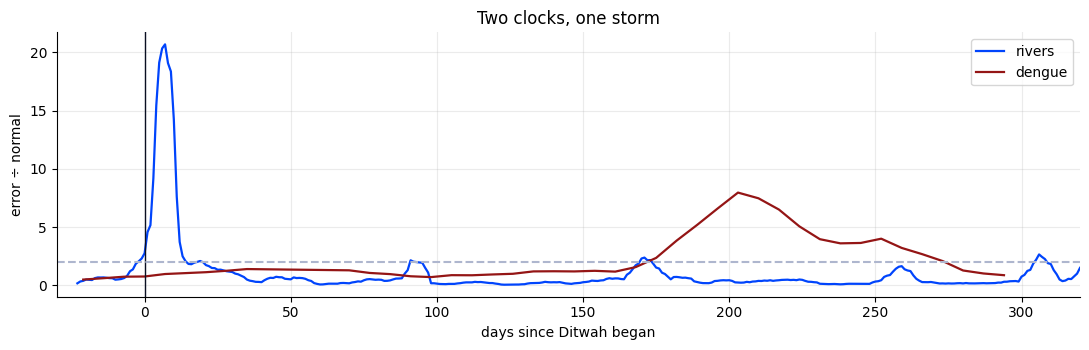


Rivers broke the moment Ditwah hit. Dengue held through Ditwah and broke months later, in a different event.
The shock you're watching isn't always the one that breaks your model. That's why the alarm never switches off.


In [ ]:
#@title Run me: two clocks, one storm

def clock(track):
    """Each day's (or week's) error ÷ normal error, smoothed, counted from the day Ditwah began."""
    c = CFG[track]
    ratio = LIVE[track].groupby("date").err.mean() / NORMAL_ALL[track]
    ratio = ratio.rolling(c["window"], min_periods=1).mean()
    ratio.index = (ratio.index - DITWAH[0]).days
    return ratio


FIRST = {}
fig, ax = plt.subplots(figsize=(11, 3.6))

for track, color in [("rivers", BLUE), ("dengue", RED)]:
    s = clock(track)
    ax.plot(s.index, s.values, color=color, lw=1.6, label=track)

    after = s[s.index >= 0]
    above = after[after > 2]
    FIRST[track] = int(above.index.min()) if len(above) else None

    if FIRST[track] is None:
        print(f"{track}: error peaked at {after.max():.1f}× normal and never passed 2×")
    else:
        when = (DITWAH[0] + pd.Timedelta(days=FIRST[track])).date()
        print(f"{track}: error peaked at {after.max():.1f}× normal, first above 2× on day {FIRST[track]} ({when})")

ax.axvline(0, color=INK, lw=1)
ax.axhline(2, color=GREY, ls="--")
ax.set_xlim(-30, 320)
ax.set_xlabel("days since Ditwah began")
ax.set_ylabel("error ÷ normal")
ax.set_title("Two clocks, one storm")
ax.legend()

plt.tight_layout()
plt.show()


r, d = FIRST.get("rivers"), FIRST.get("dengue")
if r is not None and d is not None and d > r + 60:
    print("\nRivers broke the moment Ditwah hit. Dengue held through Ditwah and broke months later, in a different event.")
    print("The shock you're watching isn't always the one that breaks your model. That's why the alarm never switches off.")

---
## Your challenge: the graded part
This notebook isn't graded. The Ditwah Challenge is: a separate application you build on your own, due Saturday 31 October.

**Build a heat-stress early warning.** Pick three districts, forecast the heat index a few days ahead, and flag the days that cross the Met Department's caution level. Prove it the way we did today: as-of data, an honest split, baselines, two model families, a stress test and a policy.

- **Submit:** one zip with your notebook, your data and a two-page report, on the form: https://forms.gle/q6F4W2gWyJPcaqdj9
- **Deadline:** Saturday 31 October, 11:59 pm.
- **The brief and a data starter:** in the Model X 2.0 × Zuu Crew WhatsApp group.
- **Prizes:** the top three each win one Zuu Crew course free, or 40% off a full pathway.

---
## Before Friday 23 October: your Model X checklist
1. List every feature in your own model and **when it's published**. Shift or drop anything you wouldn't have had in time.
2. Put a **naive baseline** next to your model's score.
3. **Plot your error over time**, not just one number.
4. **Health teams:** ask your system *"What medicine should I take?"* If it answers, fix that. Model X is non-clinical.

Stuck? Ask in the Model X 2.0 × Zuu Crew WhatsApp group.